In [825]:
import numpy as np
from hcipy import * 
import os
import sys
import matplotlib.pyplot as plt
import matplotlib.pylab as pylab
from scipy.optimize import curve_fit

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2
from psfGenerator import PsfGenerator

In [826]:
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (12, 5),
         'axes.labelsize': 'large',
         'axes.titlesize':'large',
         'xtick.labelsize':'medium',
         'ytick.labelsize':'medium',
         'font.family':'serif'}
pylab.rcParams.update(params)

def colorbar(mappable):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    import matplotlib.pyplot as plt
    last_axes = plt.gca()
    ax = mappable.axes
    fig = ax.figure
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    cbar = fig.colorbar(mappable, cax=cax)
    plt.sca(last_axes)
    return cbar

### magellan pupil

In [827]:
wavelength = 764E-9
wavelength_normalized = wavelength / 656E-9
grating_angle = 0
grating_frequency = 10

mono_bw = 1E-9
bb_bw = 120E-9

PsfGen_broad = PsfGenerator(sparkles=False,center_wavelength=wavelength_normalized,bandwidth=bb_bw/wavelength, focal_sampling=6,focal_extent = grating_frequency*1.5,grating_angle=grating_angle, fx=grating_frequency, fy = grating_frequency, mask=False)


psf1 = PsfGen_broad.psf(magnitude_x=0,magnitude_y=0)

OldStyleField(0.98384064)

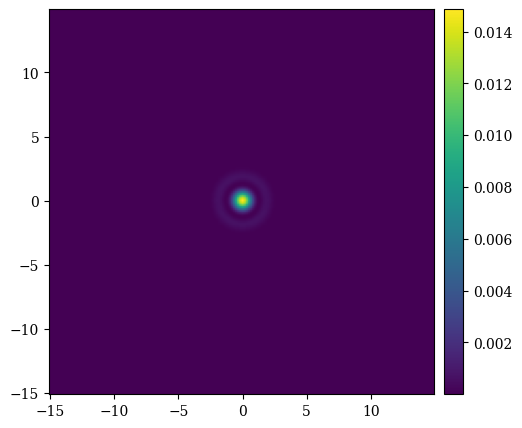

In [828]:
a = imshow_field(psf1)
colorbar(a)
np.sum(psf1)

In [829]:
wavelength = 764E-9
wavelength_normalized = wavelength / 656E-9
grating_angle = 0
grating_frequency = 2
focal_extent = 10

mono_bw = 1E-9 #monochromatic bandwidth
bb_bw = 120E-9 #broadband bandwidth

PsfGen_broad = PsfGenerator(sparkles=False,center_wavelength=wavelength_normalized,bandwidth=bb_bw/wavelength, focal_sampling=6,focal_extent = focal_extent,grating_angle=grating_angle, fx=grating_frequency, fy = grating_frequency, mask=False)

psf_bb = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0)
norm_factor = np.max(psf_bb)
psf_bb = psf_bb / norm_factor

psf_disp = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0.05) / norm_factor

psf_bb = np.log10(psf_bb+1E-13)
psf_disp = np.log10(psf_disp+1E-13)

coron_psf_bb = PsfGen_broad.coron_psf(num_photons=1E12,ptv=0) / norm_factor
coron_psf_disp = PsfGen_broad.coron_psf(magnitude_x = 0,magnitude_y = 0.01,num_photons=1E12,ptv=0) / norm_factor

coron_psf_bb = np.log10(coron_psf_bb+1E-13)
coron_psf_disp = np.log10(coron_psf_disp+1E-13)


In [830]:
sum(coron_psf_disp)

np.float64(-85806.23817080916)

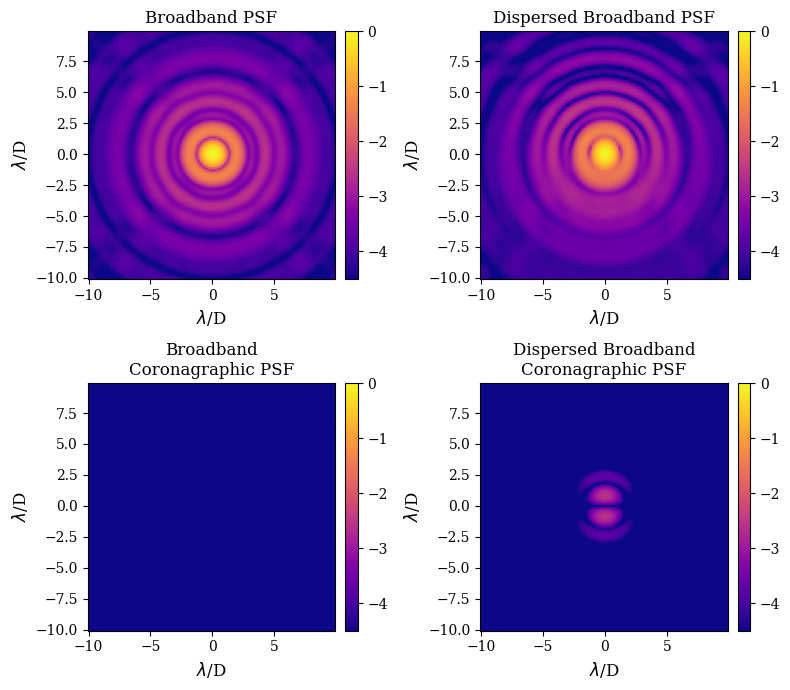

In [831]:
color = 'plasma'
fig, axs = plt.subplots(2,2,figsize=(8,7))

a = imshow_field(psf_bb,cmap=color,vmax=0,vmin=-4.5,ax=axs[0,0])
ca = colorbar(a)
axs[0,0].set_title('Broadband PSF')
axs[0,0].set_xlabel(r'$\lambda$/D')
axs[0,0].set_ylabel(r'$\lambda$/D')

b = imshow_field(psf_disp,cmap=color,vmax=0,vmin=-4.5,ax = axs[0,1])
cb = colorbar(b)
axs[0,1].set_title('Dispersed Broadband PSF')
axs[0,1].set_xlabel(r'$\lambda$/D')
axs[0,1].set_ylabel(r'$\lambda$/D')

c = imshow_field(coron_psf_bb,cmap=color,vmax=0,vmin=-4.5,ax = axs[1,0])
cc = colorbar(c)
axs[1,0].set_title('Broadband\nCoronagraphic PSF')
axs[1,0].set_xlabel(r'$\lambda$/D')
axs[1,0].set_ylabel(r'$\lambda$/D')

d = imshow_field(coron_psf_disp,cmap=color,vmax=0,vmin=-4.5,ax = axs[1,1])
cd = colorbar(d)
axs[1,1].set_title('Dispersed Broadband\nCoronagraphic PSF')
axs[1,1].set_xlabel(r'$\lambda$/D')
axs[1,1].set_ylabel(r'$\lambda$/D')

fig.tight_layout(h_pad=1)

### exactly the same thing but with the GMT pupil

Text(0.5, 1.0, 'GMT  pupil')

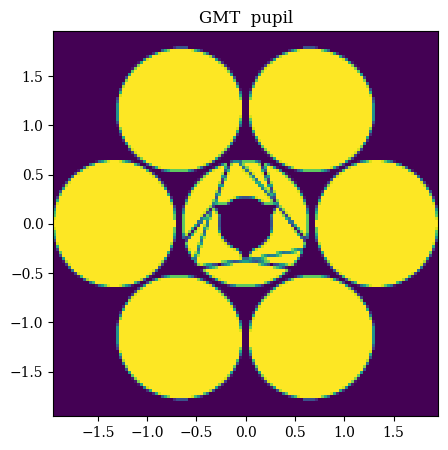

In [832]:
gmt_pupgrid = make_pupil_grid(128,diameter=1)
gmt_ap = evaluate_supersampled(make_gmt_aperture(normalized=True),gmt_pupgrid,4,statistic='mean')

pupil = gmt_ap
pupil_scaled = Field(pupil,pupil.grid.scaled(25.4/6.5))
imshow_field(pupil_scaled)
plt.title('GMT  pupil')

In [833]:
wavelength = 764E-9
wavelength_normalized = wavelength / 656E-9
grating_angle = 0
focal_extent = 10

mono_bw = 1E-9
bb_bw = 120E-9

PsfGen_broad = PsfGenerator(sparkles=False,telescope_pupil=pupil_scaled,center_wavelength=wavelength_normalized,bandwidth=bb_bw/wavelength, focal_sampling=18,focal_extent=focal_extent, mask=False)


In [834]:
gmt_psf_bb = PsfGen_broad.psf()
gmt_norm_factor = np.max(gmt_psf_bb)
gmt_psf_bb /= gmt_norm_factor

gmt_psf_disp = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0.01) / gmt_norm_factor

gmt_psf_bb = np.log10(gmt_psf_bb+1E-13) 
gmt_psf_disp = np.log10(gmt_psf_disp+1E-13)

coron_gmt_psf_bb = PsfGen_broad.coron_psf(num_photons=1E12,ptv=0) / gmt_norm_factor
coron_gmt_psf_disp = PsfGen_broad.coron_psf(magnitude_x = 0,magnitude_y = 0.01,num_photons=1E12,ptv=0) / gmt_norm_factor

coron_gmt_psf_bb = np.log10(coron_gmt_psf_bb+1E-13)
coron_gmt_psf_disp = np.log10(coron_gmt_psf_disp+1E-13)

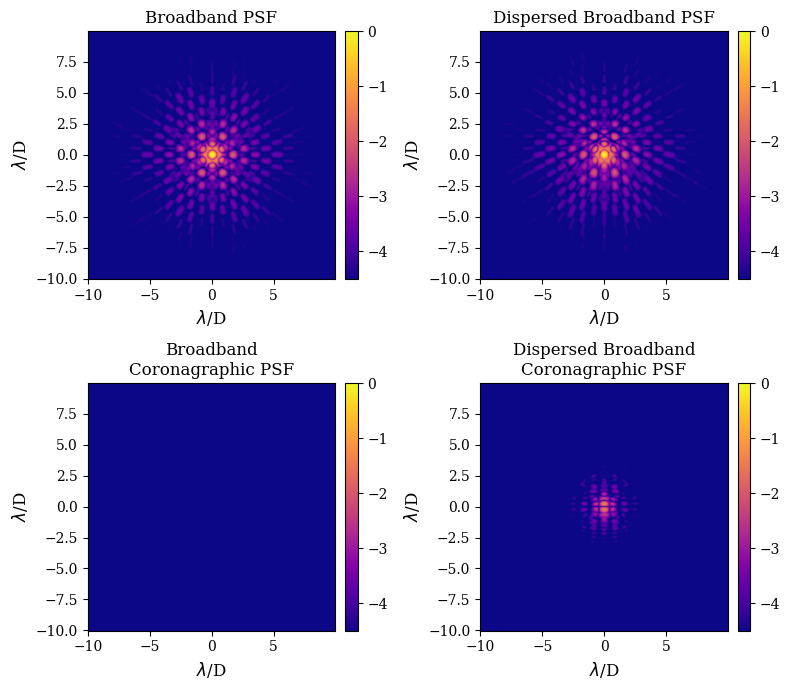

In [835]:
color = 'plasma'
fig, axs = plt.subplots(2,2,figsize=(8,7))

a = imshow_field(gmt_psf_bb,cmap=color,vmax=0,vmin=-4.5,ax=axs[0,0])
ca = colorbar(a)
axs[0,0].set_title('Broadband PSF')
axs[0,0].set_xlabel(r'$\lambda$/D')
axs[0,0].set_ylabel(r'$\lambda$/D')

b = imshow_field(gmt_psf_disp,cmap=color,vmax=0,vmin=-4.5,ax = axs[0,1])
cb = colorbar(b)
axs[0,1].set_title('Dispersed Broadband PSF')
axs[0,1].set_xlabel(r'$\lambda$/D')
axs[0,1].set_ylabel(r'$\lambda$/D')

c = imshow_field(coron_gmt_psf_bb,cmap=color,vmax=0,vmin=-4.5,ax = axs[1,0])
cc = colorbar(c)
axs[1,0].set_title('Broadband\nCoronagraphic PSF')
axs[1,0].set_xlabel(r'$\lambda$/D')
axs[1,0].set_ylabel(r'$\lambda$/D')

d = imshow_field(coron_gmt_psf_disp,cmap=color,vmax=0,vmin=-4.5,ax = axs[1,1])
cd = colorbar(d)
axs[1,1].set_title('Dispersed Broadband\nCoronagraphic PSF')
axs[1,1].set_xlabel(r'$\lambda$/D')
axs[1,1].set_ylabel(r'$\lambda$/D')

fig.tight_layout(h_pad=1)

the GMT PSF is smaller than the Magellan PSF by a factor of 25.4/6.5 ~ 3.9, but PSF size relative to its own lam/D should stay the same between the two , adjisting for differences in the psf shape due to aperture shape. I think these figures would make more sense if they were scaled such that lam/D matched real units in the focal plane? that way it's pretty plain the reason /why/ the GMT is so much more sensitive to dispersion than Magellan is.

### Lyot Coronagraph Version

### Magellan

Text(0.5, 0.98, 'MagAO-X Lyot Coronagraph')

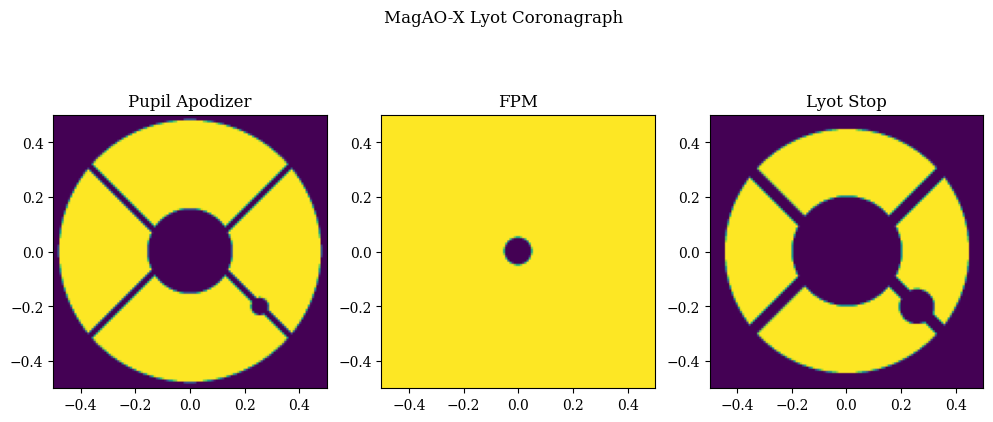

In [836]:
from lyot_stops import make_magaox_large_lyot_stop, make_magaox_bump_mask, make_gmt_lyot_aperture

pupil = make_magaox_bump_mask(normalized=True,aperture_scale='normalized')
make_lyotlg1 = make_magaox_large_lyot_stop(normalized=True,aperture_scale='normalized')

grid = make_pupil_grid(128)
lyot_fpm = evaluate_supersampled(make_circular_aperture(0.1), grid, 4) #this cannot actually be used as the fpm because it's on the wrong grid! just for show
lyot_fpm = np.abs(lyot_fpm -1)
lyotlg1 = evaluate_supersampled(make_lyotlg1,grid,4)
bump_mask = evaluate_supersampled(pupil,grid,4)

plt.subplot(1,3,1)
imshow_field(bump_mask)
plt.title('Pupil Apodizer')
plt.subplot(1,3,2)
imshow_field(lyot_fpm)
plt.title('FPM')
plt.subplot(1,3,3)
imshow_field(lyotlg1)
plt.title('Lyot Stop')
plt.suptitle('MagAO-X Lyot Coronagraph')

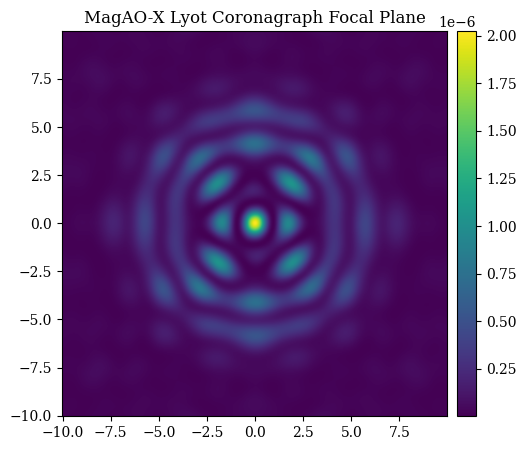

In [837]:
#now propagate through the lyot coronagraph
PsfGen_broad = PsfGenerator(sparkles=False,telescope_pupil=bump_mask,center_wavelength=wavelength_normalized,bandwidth=bb_bw/wavelength, focal_sampling=18,focal_extent = 10,grating_angle=grating_angle, fx=grating_frequency, fy = grating_frequency, mask=False)

magaox_fpm = evaluate_supersampled(make_circular_aperture(6.57), PsfGen_broad.focal_grid, 4)
magaox_fpm = np.abs(magaox_fpm - 1)

lyot_psf = PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1)
plt.figure()
a = imshow_field(lyot_psf)
colorbar(a)
plt.title('MagAO-X Lyot Coronagraph Focal Plane')
plt.show()

In [838]:
# replicate the figure from above but with the lyot coronagraph
wavelength = 764E-9
wavelength_normalized = wavelength / 656E-9
grating_angle = 0
grating_frequency = 7
focal_extent = 10

mono_bw = 1E-9 #monochromatic bandwidth
bb_bw = 120E-9 #broadband bandwidth

PsfGen_broad = PsfGenerator(sparkles=False,telescope_pupil=bump_mask,center_wavelength=wavelength_normalized,bandwidth=bb_bw/wavelength, focal_sampling=6,focal_extent = focal_extent,grating_angle=grating_angle, fx=grating_frequency, fy = grating_frequency, mask=False)

psf_bb = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0)
norm_factor = np.max(psf_bb)
psf_bb = psf_bb / norm_factor

psf_disp = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0.4) / norm_factor

psf_bb = np.log10(psf_bb+1E-13)
psf_disp = np.log10(psf_disp+1E-13)

coron_psf_bb = PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1) / norm_factor
coron_psf_disp = PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1,magnitude_x=0,magnitude_y=0.4) / norm_factor

coron_psf_bb = np.log10(coron_psf_bb+1E-13)
coron_psf_disp = np.log10(coron_psf_disp+1E-13)

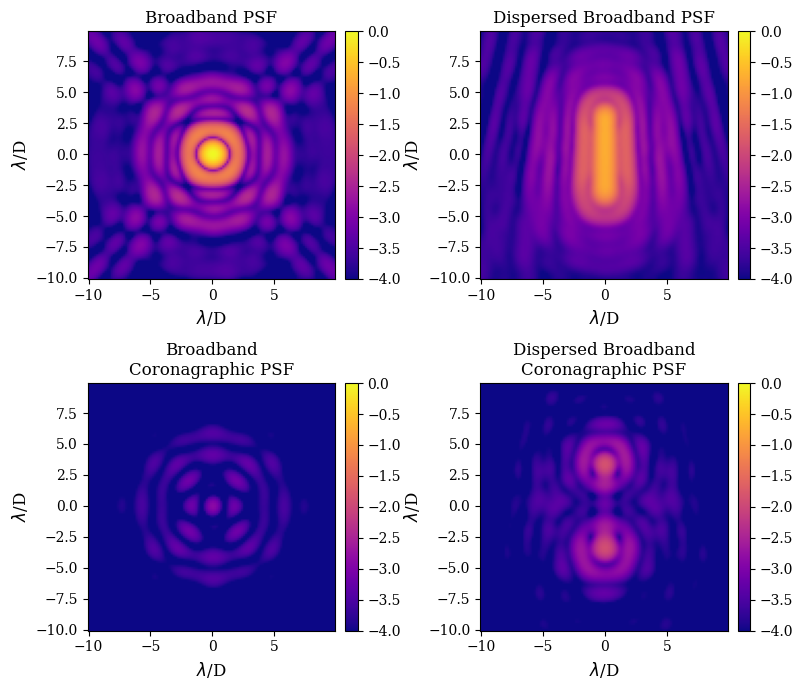

In [839]:
color = 'plasma'
fig, axs = plt.subplots(2,2,figsize=(8,7))

a = imshow_field(psf_bb,cmap=color,vmax=0,vmin=-4,ax=axs[0,0])
ca = colorbar(a)
axs[0,0].set_title('Broadband PSF')
axs[0,0].set_xlabel(r'$\lambda$/D')
axs[0,0].set_ylabel(r'$\lambda$/D')

b = imshow_field(psf_disp,cmap=color,vmax=0,vmin=-4,ax = axs[0,1])
cb = colorbar(b)
axs[0,1].set_title('Dispersed Broadband PSF')
axs[0,1].set_xlabel(r'$\lambda$/D')
axs[0,1].set_ylabel(r'$\lambda$/D')

c = imshow_field(coron_psf_bb,cmap=color,vmax=0,vmin=-4,ax = axs[1,0])
cc = colorbar(c)
axs[1,0].set_title('Broadband\nCoronagraphic PSF')
axs[1,0].set_xlabel(r'$\lambda$/D')
axs[1,0].set_ylabel(r'$\lambda$/D')

d = imshow_field(coron_psf_disp,cmap=color,vmax=0,vmin=-4, ax = axs[1,1])
cd = colorbar(d)
axs[1,1].set_title('Dispersed Broadband\nCoronagraphic PSF')
axs[1,1].set_xlabel(r'$\lambda$/D')
axs[1,1].set_ylabel(r'$\lambda$/D')

fig.tight_layout(h_pad=1)

### GMT

Text(0.5, 1.0, 'GMT  pupil')

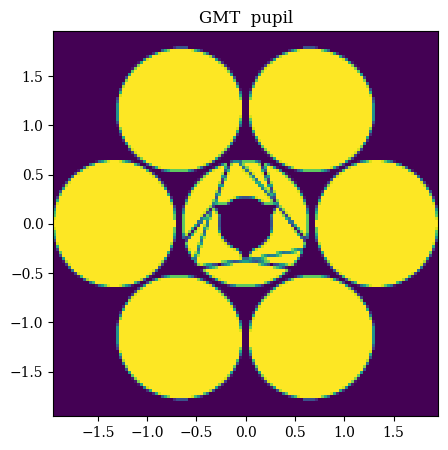

In [840]:
gmt_pupgrid = make_pupil_grid(128,diameter=1)
gmt_ap = evaluate_supersampled(make_gmt_aperture(normalized=True),gmt_pupgrid,4,statistic='mean')

pupil = gmt_ap
pupil_scaled = Field(pupil,pupil.grid.scaled(25.4/6.5))
imshow_field(pupil_scaled)
plt.title('GMT  pupil')

Text(0.5, 0.98, 'GMT Lyot Coronagraph')

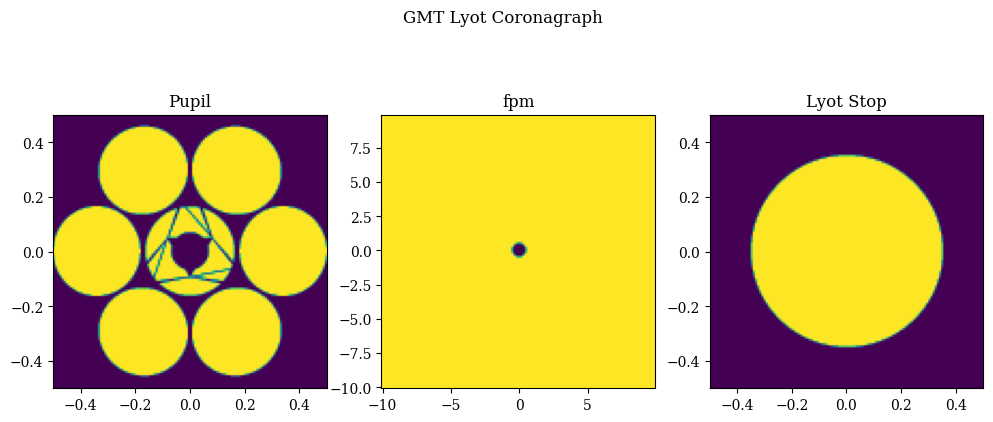

In [841]:
pupil_scaled = Field(pupil,pupil.grid.scaled(25.4/6.5))
pupil_norm =  Field(pupil,pupil.grid)
gmt_lyot = evaluate_supersampled(make_circular_aperture(0.7),gmt_pupgrid,4,statistic='mean')
#gmt_lyot_scaled = Field(gmt_lyot,gmt_lyot.grid.scaled(25.4/6.5))
gmt_lyot_scaled = Field(gmt_lyot,gmt_lyot.grid.scaled(1))
gmt_fpm = evaluate_supersampled(make_circular_aperture(1), PsfGen_broad.focal_grid, 4)
gmt_fpm = np.abs(gmt_fpm - 1)



plt.subplot(1,3,1)
imshow_field(pupil)
plt.title('Pupil')
plt.subplot(1,3,2)
imshow_field(gmt_fpm)
plt.title('fpm')
plt.subplot(1,3,3)
imshow_field(gmt_lyot_scaled)
plt.title('Lyot Stop')
plt.suptitle('GMT Lyot Coronagraph')

In [842]:
wavelength = 615E-9
wavelength_normalized = 1
grating_angle = 0
focal_extent = 10

mono_bw = 1E-9
bb_bw = 120E-9

PsfGen_broad = PsfGenerator(sparkles=False,telescope_pupil=pupil,center_wavelength=wavelength_normalized,bandwidth=bb_bw/wavelength, focal_sampling=18,focal_extent=focal_extent, mask=False)
gmt_fpm = evaluate_supersampled(make_circular_aperture(6), PsfGen_broad.focal_grid, 4)
gmt_fpm = np.abs(gmt_fpm - 1)

gmt_psf_bb = PsfGen_broad.psf()
gmt_norm_factor = np.max(gmt_psf_bb)
gmt_psf_bb /= gmt_norm_factor

gmt_psf_disp = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0.4) / gmt_norm_factor

gmt_psf_bb = np.log10(gmt_psf_bb+1E-13) 
gmt_psf_disp = np.log10(gmt_psf_disp+1E-13)

coron_gmt_psf_bb = PsfGen_broad.lyot_coron_psf(gmt_fpm,gmt_lyot_scaled) / gmt_norm_factor
coron_gmt_psf_disp = PsfGen_broad.lyot_coron_psf(gmt_fpm,gmt_lyot_scaled,magnitude_x = 0,magnitude_y = 0.4) / gmt_norm_factor

coron_gmt_psf_bb = np.log10(coron_gmt_psf_bb+1E-13)
coron_gmt_psf_disp = np.log10(coron_gmt_psf_disp+1E-13)

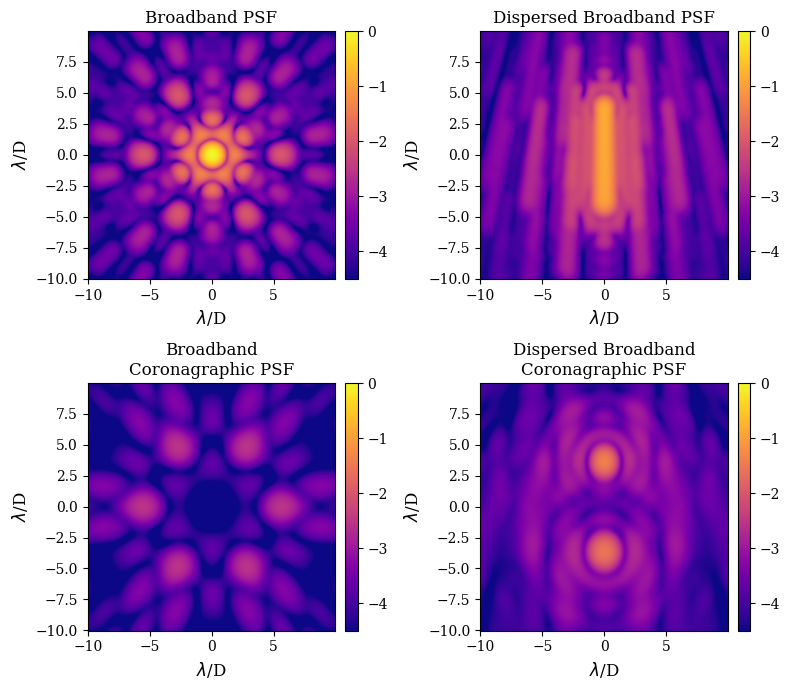

In [843]:
color = 'plasma'
fig, axs = plt.subplots(2,2,figsize=(8,7))

a = imshow_field(gmt_psf_bb,cmap=color,vmax=0,vmin=-4.5,ax=axs[0,0])
ca = colorbar(a)
axs[0,0].set_title('Broadband PSF')
axs[0,0].set_xlabel(r'$\lambda$/D')
axs[0,0].set_ylabel(r'$\lambda$/D')

b = imshow_field(gmt_psf_disp,cmap=color,vmax=0,vmin=-4.5,ax = axs[0,1])
cb = colorbar(b)
axs[0,1].set_title('Dispersed Broadband PSF')
axs[0,1].set_xlabel(r'$\lambda$/D')
axs[0,1].set_ylabel(r'$\lambda$/D')

c = imshow_field(coron_gmt_psf_bb,cmap=color,vmax=0,vmin=-4.5,ax = axs[1,0])
cc = colorbar(c)
axs[1,0].set_title('Broadband\nCoronagraphic PSF')
axs[1,0].set_xlabel(r'$\lambda$/D')
axs[1,0].set_ylabel(r'$\lambda$/D')

d = imshow_field(coron_gmt_psf_disp,cmap=color,vmax=0,vmin=-4.5,ax = axs[1,1])
cd = colorbar(d)
axs[1,1].set_title('Dispersed Broadband\nCoronagraphic PSF')
axs[1,1].set_xlabel(r'$\lambda$/D')
axs[1,1].set_ylabel(r'$\lambda$/D')

fig.tight_layout(h_pad=1)

### Real Dispersion Units
now that I have coronagraphic images from each telescope, I need to convert the dispersion into real units. Both telescopes have the same size PSF right now because everything in the focal plane is measured in lam/D. I need to measure the elongation of the psf core and convert that into mas/um of dispersion given the wavelength and waveband. Then, I can apply two different amounts of dispersion and show how the coronagraph leakage starts earlier in the GMT system than in MagAO-X.

In [844]:
focal_extent = 10
PsfGen_broad = PsfGenerator(sparkles=False,telescope_pupil=bump_mask,center_wavelength=wavelength_normalized,bandwidth=bb_bw/wavelength, focal_sampling=6,focal_extent =focal_extent,mask=False)
gmt_PsfGen_broad = PsfGenerator(sparkles=False,telescope_pupil=pupil,center_wavelength=wavelength_normalized,bandwidth=bb_bw/wavelength, focal_sampling=6,focal_extent=focal_extent, mask=False)
mag_psf_bb = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0) #redefine psf here because the old one is log scale
gmt_psf_bb = gmt_PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0) 

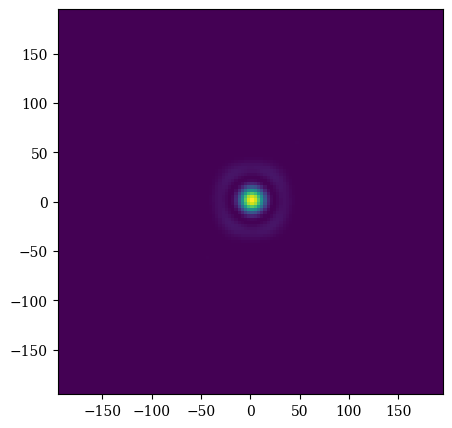

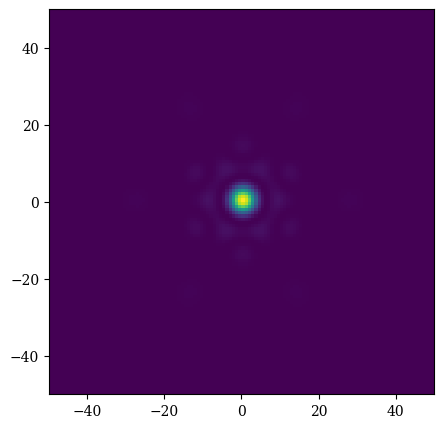

In [845]:
lam = 615E-9 # r prime filter on magaox
band = 110E-9 # r prim filter bandpass
D_magellan = 6.5 
D_gmt = 25.4

res_magellan = (lam / D_magellan) * 206265 * 1000 #resolution in mas - [mas/(lam/D)]
res_gmt = (lam / D_gmt) * 206265 * 1000

extent_magellan = res_magellan * focal_extent *2 #extent of the focal plane in mas 
extent_gmt = res_gmt * focal_extent *2

mas_focus_magellan = make_pupil_grid(np.sqrt(psf_bb.size),extent_magellan)
mas_focus_gmt = make_pupil_grid(np.sqrt(gmt_psf_bb.size),extent_gmt)

focal_plane_magellan = Field(mag_psf_bb,mas_focus_magellan)
imshow_field(focal_plane_magellan)

plt.figure()
focal_plane_gmt = Field(gmt_psf_bb,mas_focus_gmt)
imshow_field(focal_plane_gmt)

In [846]:
#now calculate the size of the central PSF in mas
def gauss(x,mu,sigma2):
    return np.exp(-(x-mu)**2 / (2 * sigma2) )

def isolate_gaussian(data):
    mid = np.argmax(data)
    first_derivative = np.gradient(data) 

    valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

    left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
    right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

    if left_valley is not None:
        data[0:left_valley] = 0
        #right_valley -= left_valley

    if right_valley is not None:
        data[right_valley:len(data)-1] = 0
        #print(right_valley)

    return data

def fwhm(data,mean_est=0):
    isolated = isolate_gaussian(data)
    x = np.arange(len(isolated))
    popt = curve_fit(gauss,x,isolated,p0=np.array([mean_est,100]))

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return fwhm, mu, sigma

#define a function that takes in the psf and spits out the vertical FWHM, with the option to provide the plot for diagnostic purposes
def psf_vertical_fwhm(data,plotted=False):
    sliced = data.shaped[:,int(np.sqrt(data.size)/2)]
    sliced /= sliced.max()
    s = isolate_gaussian(sliced)
    width, mean, sd = fwhm(s,mean_est = len(sliced)/2 )

    if plotted:
        x = np.arange(len(s))
        #print(f'FWHM: {width}')

        plt.figure()
        plt.plot(x,s,'-o',label='Data')
        plt.plot(x,gauss(x,mean,sd),'r-',label='Fitted Gaussian')
        plt.vlines(mean - width/2,0,1,'gray',label=f'FWHM: {width:.3f}')
        plt.vlines(mean + width/2,0,1,'gray')
        plt.legend()
        plt.show()

    return width

/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_78847/3168284201.py:3: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


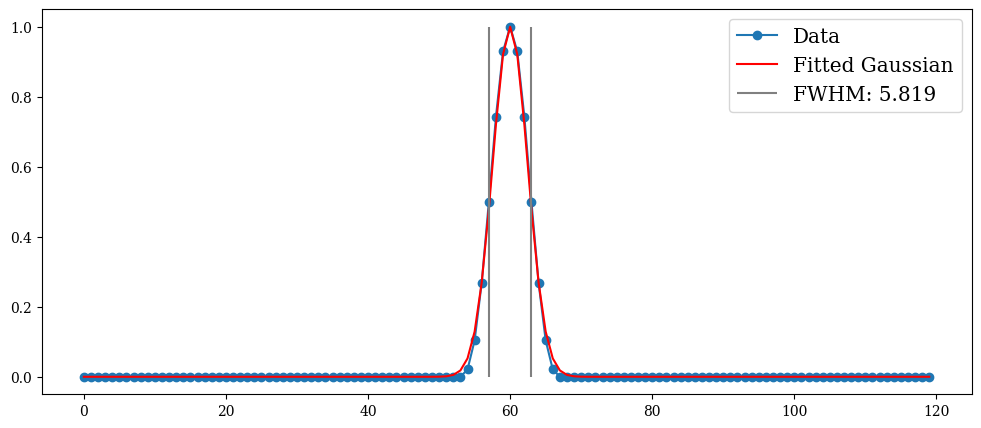

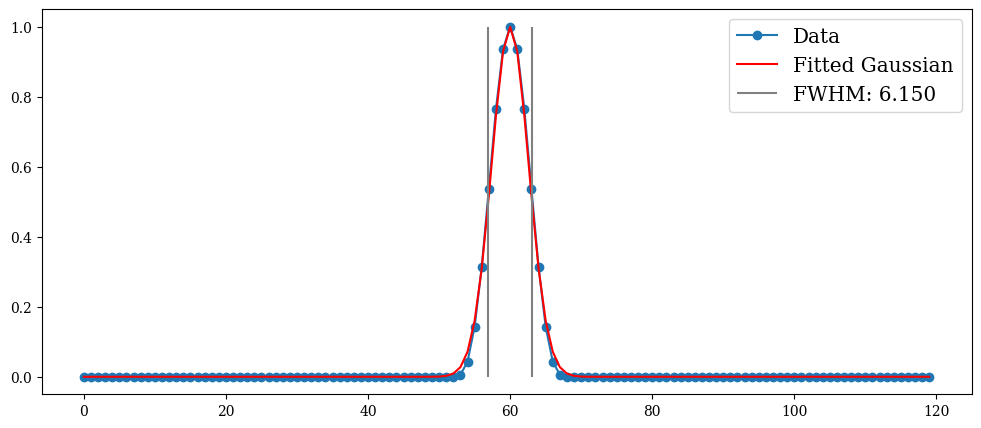

In [847]:
fwhm_mag = psf_vertical_fwhm(focal_plane_magellan.copy(),plotted=True)
fwhm_gmt = psf_vertical_fwhm(focal_plane_gmt.copy(),plotted=True)

In [848]:
#these are in terms of pixels. To get the width in terms of mas, we need to find the number of mas / pixel and multiply our results
gmt_mas_pixel = focal_plane_gmt.grid.delta[0] #mas / pixel
mag_mas_pixel = focal_plane_magellan.grid.delta[0] #mas / pixel

fwhm_mag *= mag_mas_pixel
fwhm_gmt *= gmt_mas_pixel

print(f'FWHM Magellan PSF: {fwhm_mag:.4f} mas')
print(f'FWHM GMT PSF: {fwhm_gmt:.4f} mas')

FWHM Magellan PSF: 18.9276 mas
FWHM GMT PSF: 5.1189 mas


Elongation Magellan PSF: 1.00 mas
Elongation GMT PSF: 1.00 mas


/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_78847/3168284201.py:3: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


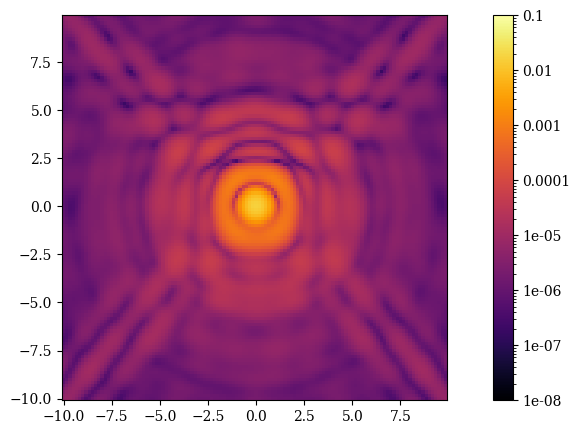

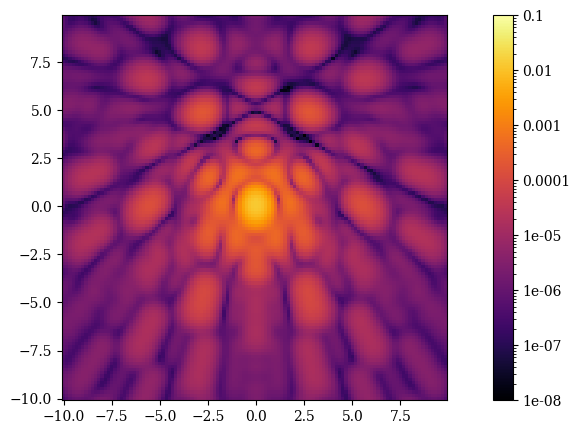

In [ ]:
#now we determine the arbitrary dispersion inputs that give us the mas dispersion that we want for each telescope
bandwidth_um = band / 1E-6

#we want to demonstrate 0 mas, 1 mas, and 10 mas dispersion levels to prove the point about coronagraph leakage. 0 mas is easy enough. 
# 1 mas
disp_magellan_1mas = 0.0233
disp_gmt_1mas = 0.0457

mag_1mas = PsfGen_broad.psf(magnitude_x=0, magnitude_y = disp_magellan_1mas) 
gmt_1mas = gmt_PsfGen_broad.psf(magnitude_y = disp_gmt_1mas)

fwhm_mag_1mas = psf_vertical_fwhm(mag_1mas.copy(),plotted=False) * mag_mas_pixel
fwhm_gmt_1mas = psf_vertical_fwhm(gmt_1mas.copy(),plotted=False) * gmt_mas_pixel

print(f'Elongation Magellan PSF: {(fwhm_mag_1mas - 18.9276):.2f} mas')
print(f'Elongation GMT PSF: {(fwhm_gmt_1mas - 5.1189):.2f} mas')

imshow_psf(mag_1mas)
plt.figure()
imshow_psf(gmt_1mas)


Elongation Magellan PSF: 10.01 mas
Elongation GMT PSF: 10.00 mas


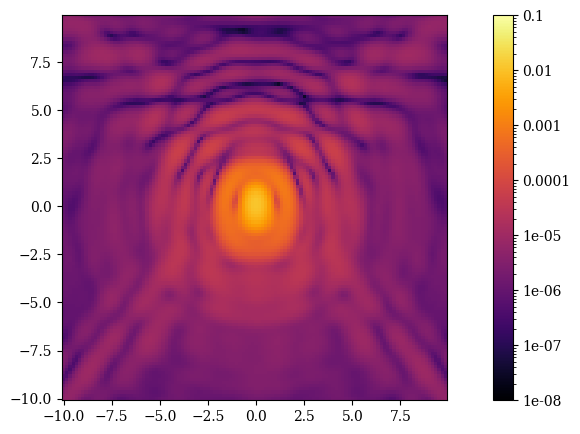

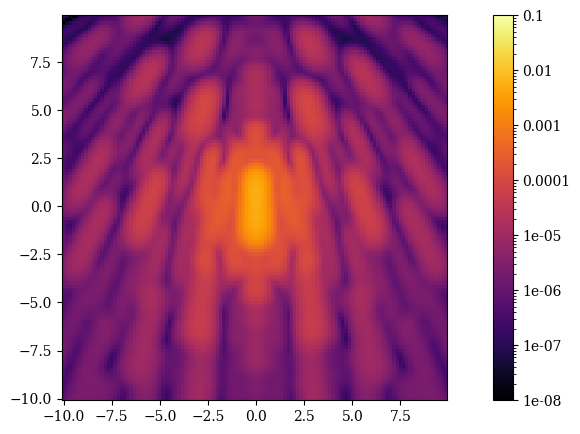

In [ ]:
# 10 mas
disp_magellan_10mas = 0.0684
disp_gmt_10mas = 0.154

mag_10mas = PsfGen_broad.psf(magnitude_x=0, magnitude_y = disp_magellan_10mas) 
gmt_10mas = gmt_PsfGen_broad.psf(magnitude_y = disp_gmt_10mas)

fwhm_mag_10mas = psf_vertical_fwhm(mag_10mas.copy(),plotted=False) * mag_mas_pixel
fwhm_gmt_10mas = psf_vertical_fwhm(gmt_10mas.copy(),plotted=False) * gmt_mas_pixel

print(f'Elongation Magellan PSF: {(fwhm_mag_10mas - 18.9276):.2f} mas')
print(f'Elongation GMT PSF: {(fwhm_gmt_10mas - 5.1189):.2f} mas')

imshow_psf(mag_10mas)
plt.show()
imshow_psf(gmt_10mas)
plt.show()

In [851]:
#now generate the same plots as above using 0 mas, 1 mas, and 10 mas
psf_bb = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0)
norm_factor = np.max(psf_bb)
psf_bb = psf_bb / norm_factor

psf_disp1 = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = disp_magellan_1mas) / norm_factor
psf_disp10 = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = disp_magellan_10mas) / norm_factor

psf_bb = np.log10(psf_bb+1E-13)
psf_disp1 = np.log10(psf_disp1+1E-13)
psf_disp10 = np.log10(psf_disp10+1E-13)

coron_psf_bb = PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1) / norm_factor
coron_psf_disp1 = PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1,magnitude_x=0,magnitude_y=disp_magellan_1mas) / norm_factor
coron_psf_disp10 = PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1,magnitude_x=0,magnitude_y=disp_magellan_10mas) / norm_factor

coron_psf_bb = np.log10(coron_psf_bb+1E-13)
coron_psf_disp1 = np.log10(coron_psf_disp1+1E-13)
coron_psf_disp10 = np.log10(coron_psf_disp10+1E-13)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/hcipy/optics/aberration.py:38: RuntimeWarning: divide by zero encountered in power
  res = Field(grid.as_('polar').r**exponent, grid)


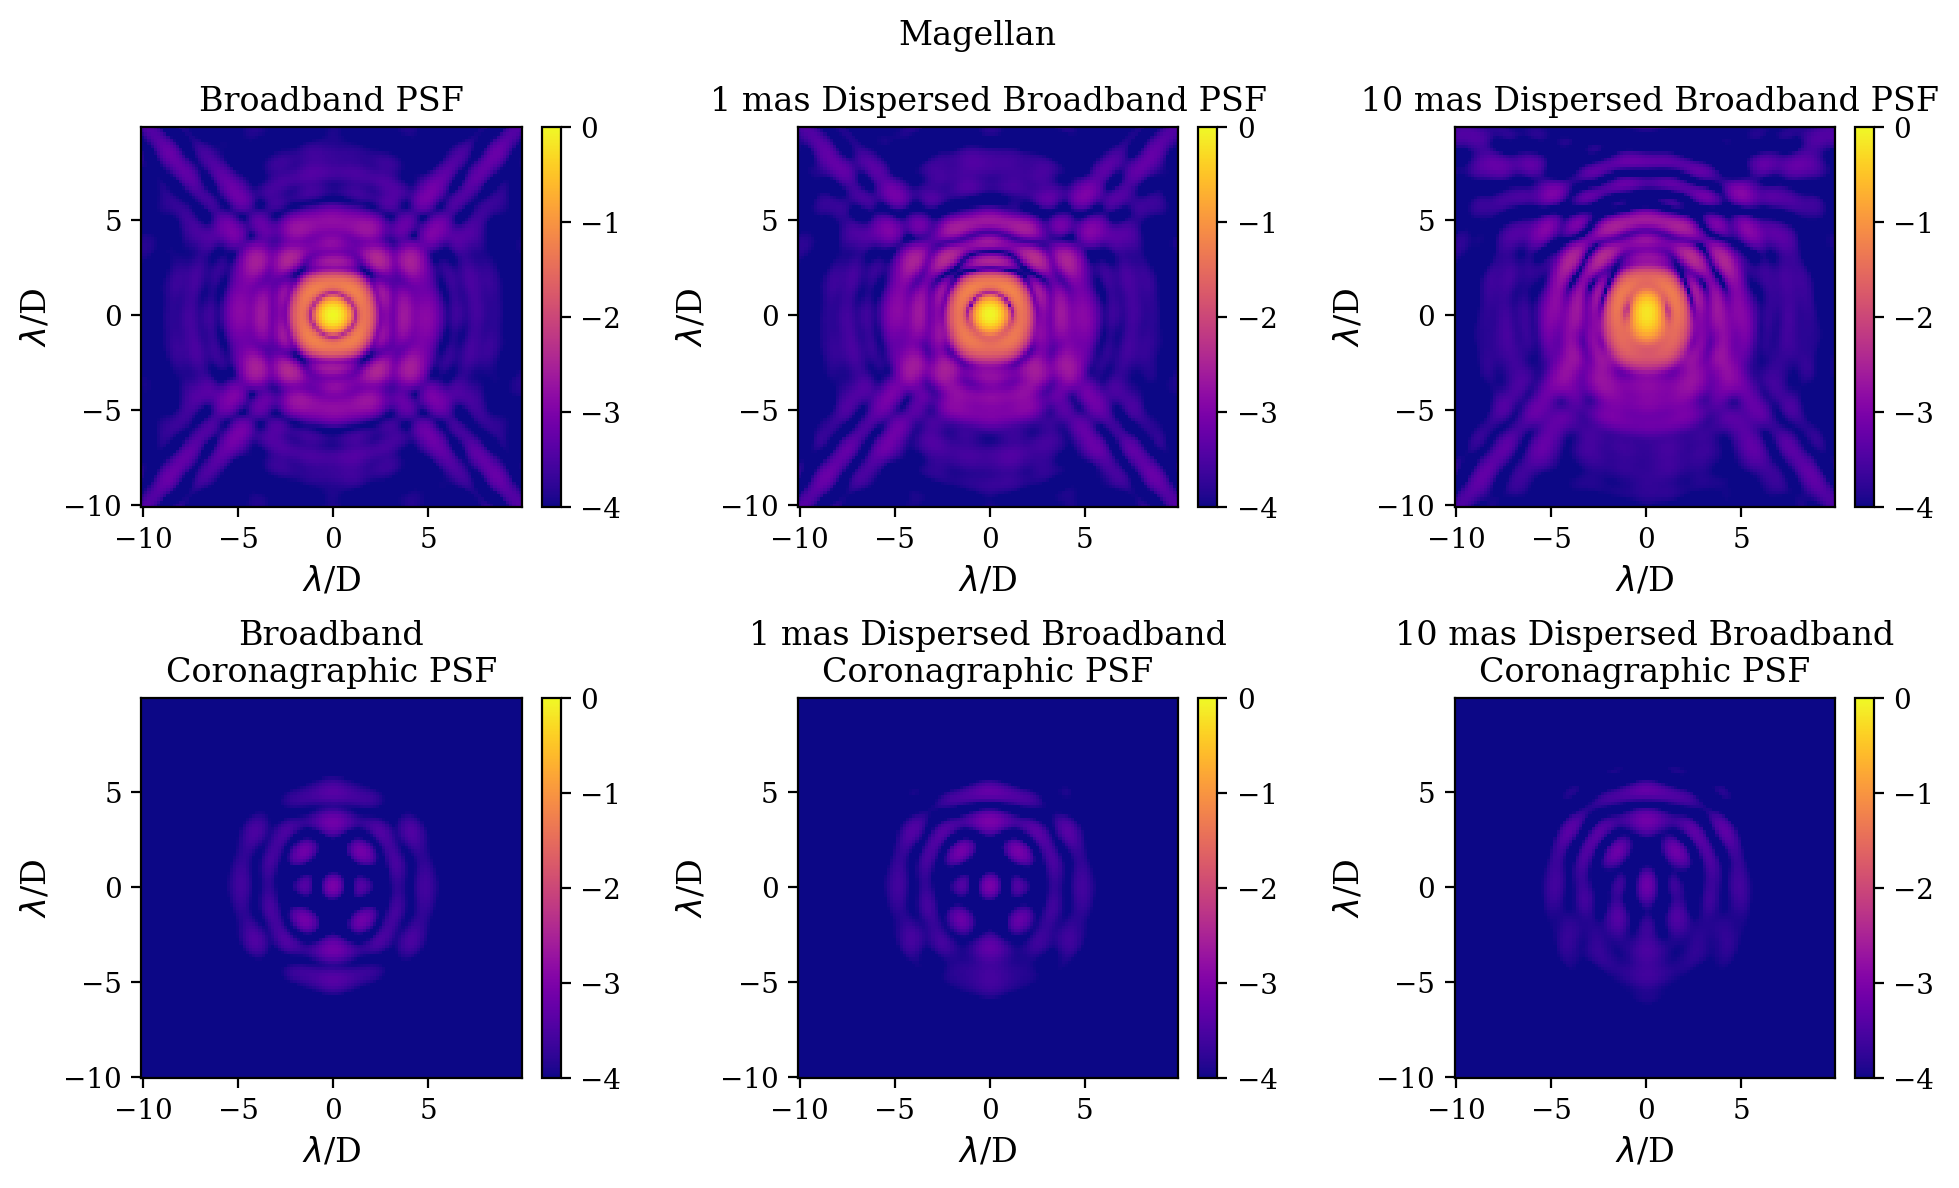

In [926]:
color = 'plasma'
fig, axs = plt.subplots(2,3,figsize=(10,6),dpi=200)

a = imshow_field(psf_bb,cmap=color,vmax=0,vmin=-4,ax=axs[0,0])
ca = colorbar(a)
axs[0,0].set_title('Broadband PSF')
axs[0,0].set_xlabel(r'$\lambda$/D')
axs[0,0].set_ylabel(r'$\lambda$/D')

b = imshow_field(psf_disp1,cmap=color,vmax=0,vmin=-4,ax = axs[0,1])
cb = colorbar(b)
axs[0,1].set_title('1 mas Dispersed Broadband PSF')
axs[0,1].set_xlabel(r'$\lambda$/D')
axs[0,1].set_ylabel(r'$\lambda$/D')

c = imshow_field(coron_psf_bb,cmap=color,vmax=0,vmin=-4,ax = axs[1,0])
cc = colorbar(c)
axs[1,0].set_title('Broadband\nCoronagraphic PSF')
axs[1,0].set_xlabel(r'$\lambda$/D')
axs[1,0].set_ylabel(r'$\lambda$/D')

d = imshow_field(coron_psf_disp1,cmap=color,vmax=0,vmin=-4, ax = axs[1,1])
cd = colorbar(d)
axs[1,1].set_title('1 mas Dispersed Broadband\nCoronagraphic PSF')
axs[1,1].set_xlabel(r'$\lambda$/D')
axs[1,1].set_ylabel(r'$\lambda$/D')

e = imshow_field(psf_disp10,cmap=color,vmax=0,vmin=-4, ax = axs[0,2])
ce = colorbar(e)
axs[0,2].set_title(' 10 mas Dispersed Broadband PSF')
axs[0,2].set_xlabel(r'$\lambda$/D')
axs[0,2].set_ylabel(r'$\lambda$/D')

f = imshow_field(coron_psf_disp10,cmap=color,vmax=0,vmin=-4, ax = axs[1,2])
cf = colorbar(f)
axs[1,2].set_title('10 mas Dispersed Broadband\nCoronagraphic PSF')
axs[1,2].set_xlabel(r'$\lambda$/D')
axs[1,2].set_ylabel(r'$\lambda$/D')

fig.suptitle('Magellan')
fig.tight_layout(h_pad=1)

In [853]:
gmt_psf_bb = gmt_PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0)
norm_factor = np.max(gmt_psf_bb)
gmt_psf_bb = gmt_psf_bb / norm_factor

gmt_psf_disp1 = gmt_PsfGen_broad.psf(magnitude_x = 0,magnitude_y = disp_gmt_1mas) / norm_factor
gmt_psf_disp10 = gmt_PsfGen_broad.psf(magnitude_x = 0,magnitude_y = disp_gmt_10mas) / norm_factor

gmt_psf_bb = np.log10(gmt_psf_bb+1E-13)
gmt_psf_disp1 = np.log10(gmt_psf_disp1+1E-13)
gmt_psf_disp10 = np.log10(gmt_psf_disp10+1E-13)

coron_gmt_psf_bb = gmt_PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1) / norm_factor
coron_gmt_psf_disp1 = gmt_PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1,magnitude_x=0,magnitude_y=disp_gmt_1mas) / norm_factor
coron_gmt_psf_disp10 = gmt_PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1,magnitude_x=0,magnitude_y=disp_gmt_10mas) / norm_factor

coron_gmt_psf_bb = np.log10(coron_gmt_psf_bb+1E-13)
coron_gmt_psf_disp1 = np.log10(coron_gmt_psf_disp1+1E-13)
coron_gmt_psf_disp10 = np.log10(coron_gmt_psf_disp10+1E-13)

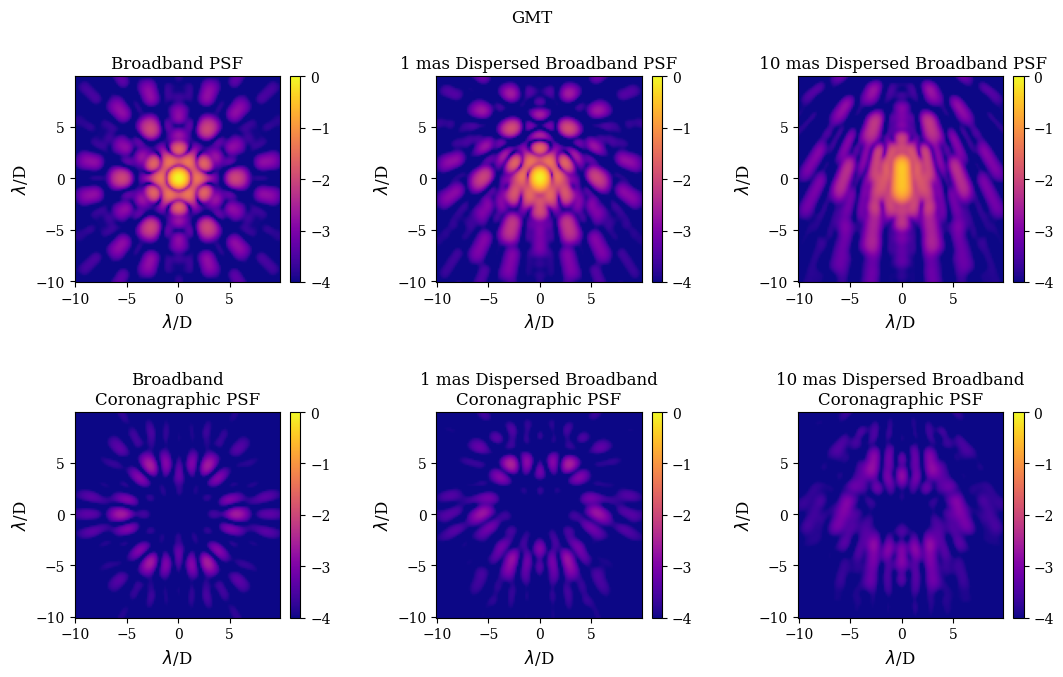

In [854]:
color = 'plasma'
fig, axs = plt.subplots(2,3,figsize=(11,7))

a = imshow_field(gmt_psf_bb,cmap=color,vmax=0,vmin=-4,ax=axs[0,0])
ca = colorbar(a)
axs[0,0].set_title('Broadband PSF')
axs[0,0].set_xlabel(r'$\lambda$/D')
axs[0,0].set_ylabel(r'$\lambda$/D')

b = imshow_field(gmt_psf_disp1,cmap=color,vmax=0,vmin=-4,ax = axs[0,1])
cb = colorbar(b)
axs[0,1].set_title('1 mas Dispersed Broadband PSF')
axs[0,1].set_xlabel(r'$\lambda$/D')
axs[0,1].set_ylabel(r'$\lambda$/D')

c = imshow_field(coron_gmt_psf_bb,cmap=color,vmax=0,vmin=-4,ax = axs[1,0])
cc = colorbar(c)
axs[1,0].set_title('Broadband\nCoronagraphic PSF')
axs[1,0].set_xlabel(r'$\lambda$/D')
axs[1,0].set_ylabel(r'$\lambda$/D')

d = imshow_field(coron_gmt_psf_disp1,cmap=color,vmax=0,vmin=-4, ax = axs[1,1])
cd = colorbar(d)
axs[1,1].set_title('1 mas Dispersed Broadband\nCoronagraphic PSF')
axs[1,1].set_xlabel(r'$\lambda$/D')
axs[1,1].set_ylabel(r'$\lambda$/D')

e = imshow_field(gmt_psf_disp10,cmap=color,vmax=0,vmin=-4, ax = axs[0,2])
ce = colorbar(e)
axs[0,2].set_title(' 10 mas Dispersed Broadband PSF')
axs[0,2].set_xlabel(r'$\lambda$/D')
axs[0,2].set_ylabel(r'$\lambda$/D')

f = imshow_field(coron_gmt_psf_disp10,cmap=color,vmax=0,vmin=-4, ax = axs[1,2])
cf = colorbar(f)
axs[1,2].set_title('10 mas Dispersed Broadband\nCoronagraphic PSF')
axs[1,2].set_xlabel(r'$\lambda$/D')
axs[1,2].set_ylabel(r'$\lambda$/D')

fig.suptitle('GMT')
fig.tight_layout(h_pad=1)

Elongation Magellan PSF: 5.01 mas
Elongation GMT PSF: 5.00 mas


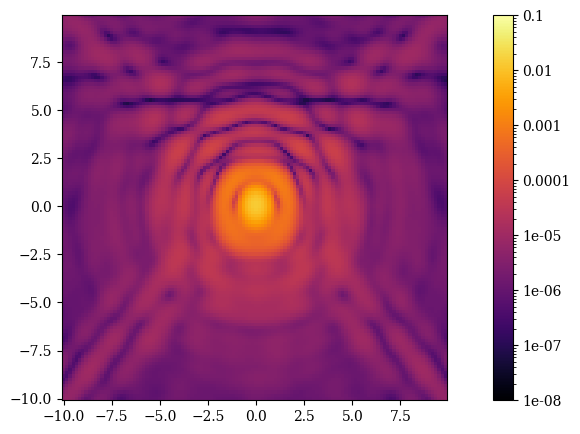

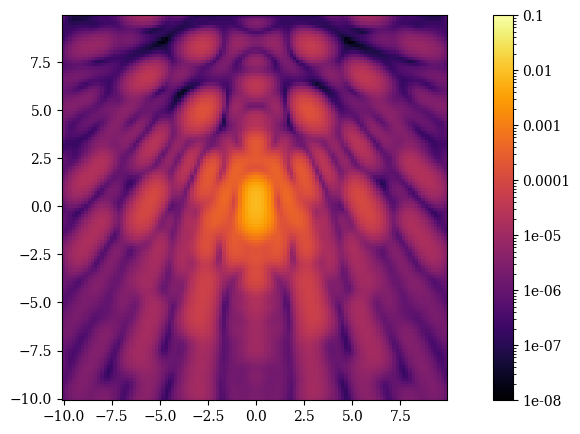

In [ ]:
#ok, 1 and 10 isn't a great option. how about 5 and 30?
# 5 mas
disp_magellan_5mas = 0.0494
disp_gmt_5mas = 0.1006

mag_5mas = PsfGen_broad.psf(magnitude_x=0, magnitude_y = disp_magellan_5mas) 
gmt_5mas = gmt_PsfGen_broad.psf(magnitude_y = disp_gmt_5mas)

fwhm_mag_5mas = psf_vertical_fwhm(mag_5mas.copy(),plotted=False) * mag_mas_pixel
fwhm_gmt_5mas = psf_vertical_fwhm(gmt_5mas.copy(),plotted=False) * gmt_mas_pixel

print(f'Elongation Magellan PSF: {(fwhm_mag_5mas - 18.9276):.2f} mas')
print(f'Elongation GMT PSF: {(fwhm_gmt_5mas - 5.1189):.2f} mas')

imshow_psf(mag_5mas)
plt.figure()
imshow_psf(gmt_5mas)


Elongation Magellan PSF: 24.77 mas
Elongation GMT PSF: 24.28 mas


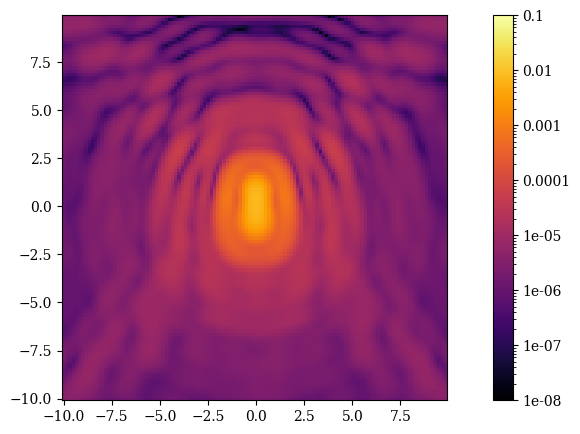

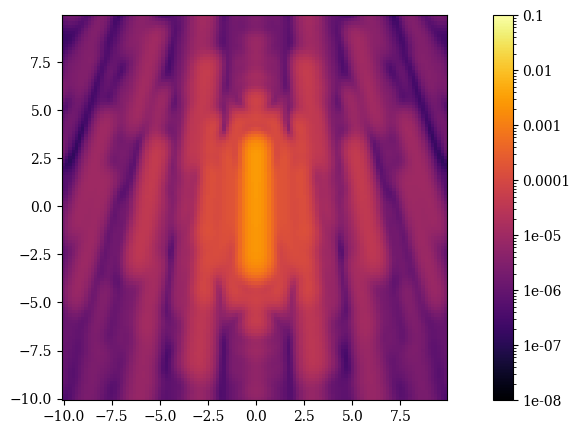

In [ ]:
# 25 mas
disp_magellan_25mas = 0.11
disp_gmt_25mas = 0.3112

mag_25mas = PsfGen_broad.psf(magnitude_x=0, magnitude_y = disp_magellan_25mas) 
gmt_25mas = gmt_PsfGen_broad.psf(magnitude_y = disp_gmt_25mas)

fwhm_mag_25mas = psf_vertical_fwhm(mag_25mas.copy(),plotted=False) * mag_mas_pixel
fwhm_gmt_25mas = psf_vertical_fwhm(gmt_25mas.copy(),plotted=False) * gmt_mas_pixel

print(f'Elongation Magellan PSF: {(fwhm_mag_25mas - 18.9276):.2f} mas')
print(f'Elongation GMT PSF: {(fwhm_gmt_25mas - 5.1189):.2f} mas')

# imshow_psf(mag_25mas)
# plt.figure()
# imshow_psf(gmt_25mas)

In [912]:
#now generate the same plots as above using 0 mas, 1 mas, and 10 mas
psf_bb = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0)
norm_factor = np.max(psf_bb)
psf_bb = psf_bb / norm_factor

psf_disp5 = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = disp_magellan_5mas) / norm_factor
psf_disp25 = PsfGen_broad.psf(magnitude_x = 0,magnitude_y = disp_magellan_25mas) / norm_factor

print(np.sum(psf_bb))
print(np.sum(psf_disp5))
print(np.sum(psf_disp25))

psf_bb = np.log10(psf_bb+1E-13)
psf_disp5 = np.log10(psf_disp5+1E-13)
psf_disp25 = np.log10(psf_disp25+1E-13)

coron_psf_bb = PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1) / norm_factor
coron_psf_disp5 = PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1,magnitude_x=0,magnitude_y=disp_magellan_5mas) / norm_factor
coron_psf_disp25 = PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1,magnitude_x=0,magnitude_y=disp_magellan_25mas) / norm_factor

print(np.sum(coron_psf_bb)/np.sum(psf_bb))
print(np.sum(coron_psf_disp5)/np.sum(psf_disp5))
print(np.sum(coron_psf_disp25)/np.sum(psf_disp25))

coron_psf_bb = np.log10(coron_psf_bb+1E-13)
coron_psf_disp5 = np.log10(coron_psf_disp5+1E-13)
coron_psf_disp25 = np.log10(coron_psf_disp25+1E-13)

55.16611233235647
55.16682042002514
55.16077409910744
-1.6756579737715167e-05
-1.6420286165275855e-05
-1.5524488062417706e-05


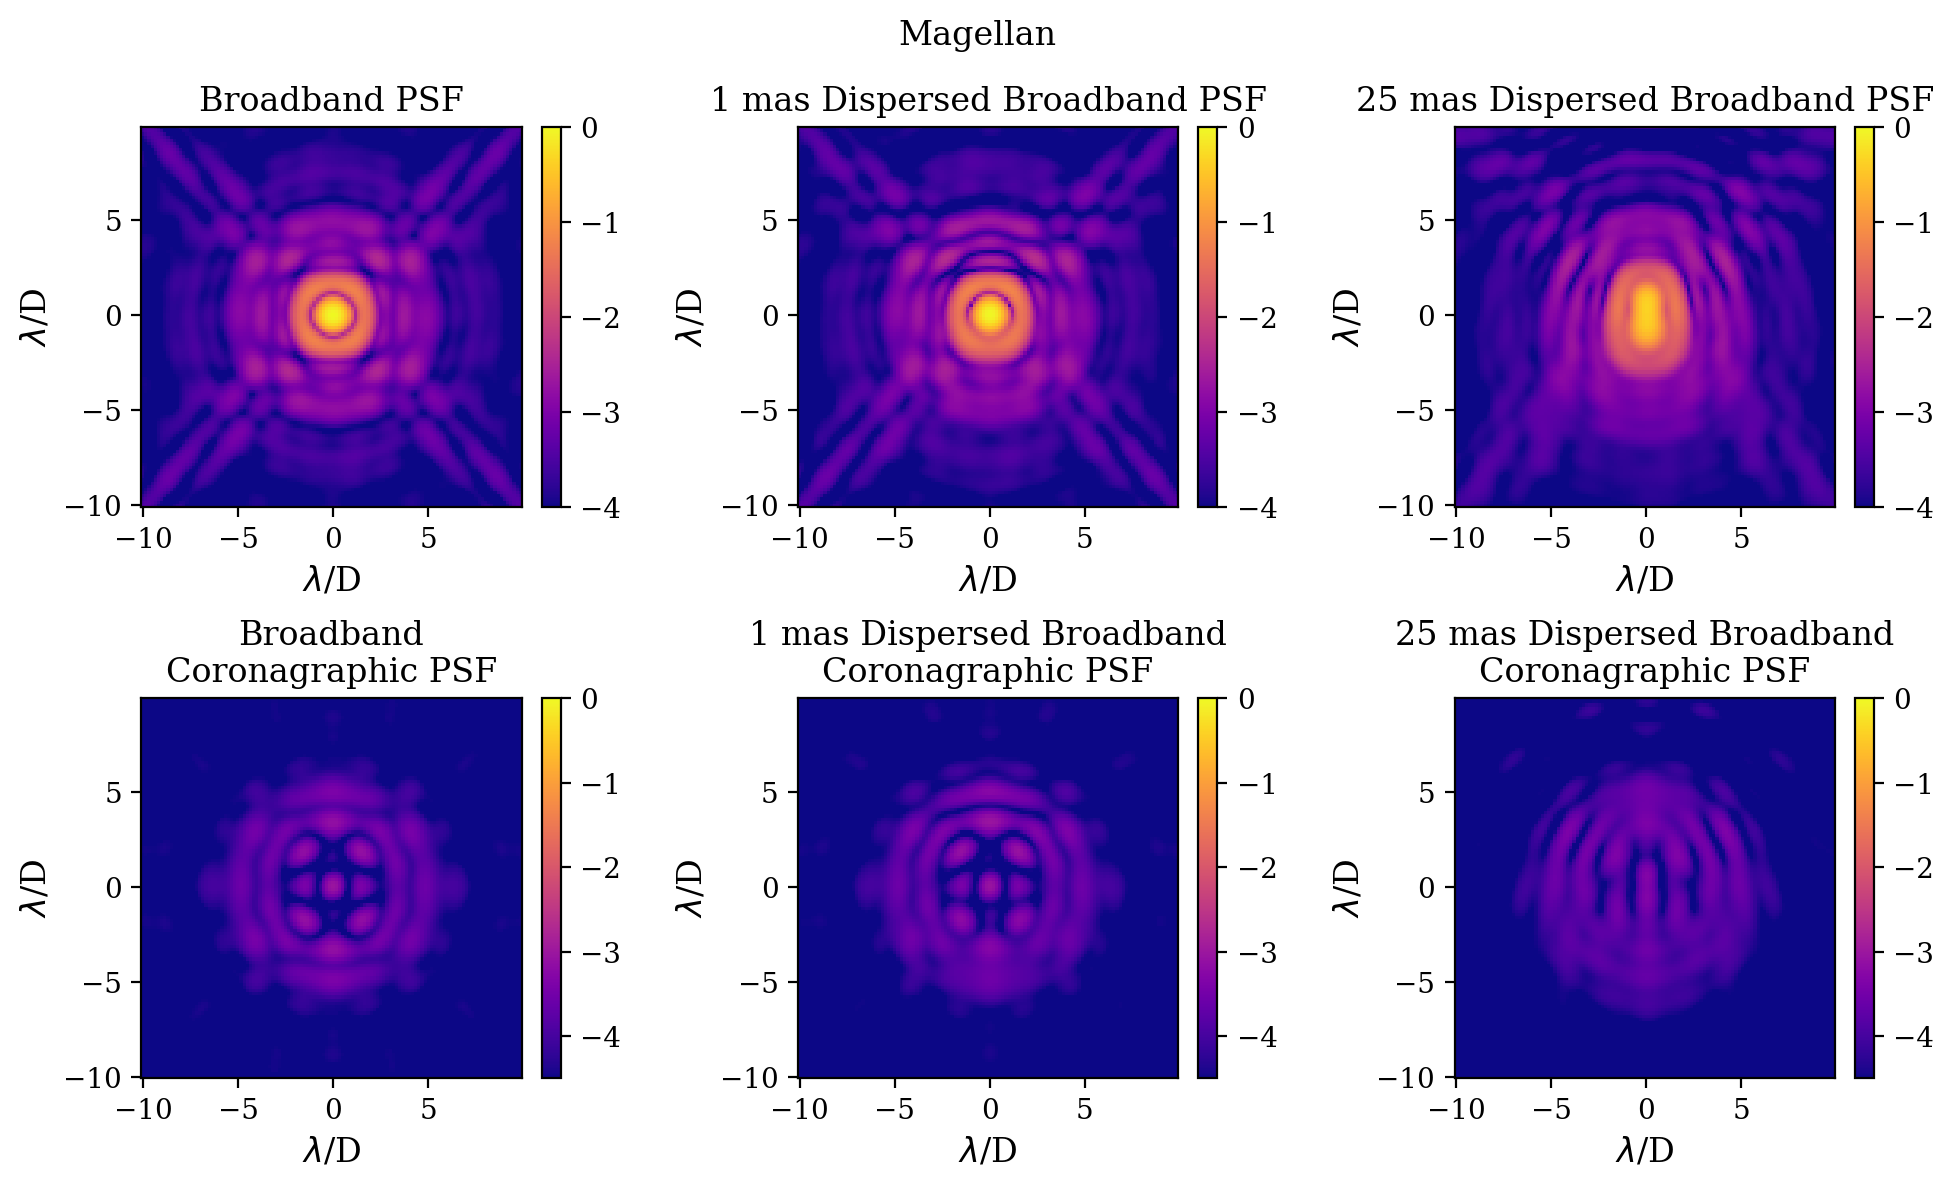

In [927]:
color = 'plasma'
fig, axs = plt.subplots(2,3,figsize=(10,6),dpi=200)

a = imshow_field(psf_bb,cmap=color,vmax=0,vmin=-4,ax=axs[0,0])
ca = colorbar(a)
axs[0,0].set_title('Broadband PSF')
axs[0,0].set_xlabel(r'$\lambda$/D')
axs[0,0].set_ylabel(r'$\lambda$/D')

b = imshow_field(psf_disp1,cmap=color,vmax=0,vmin=-4,ax = axs[0,1])
cb = colorbar(b)
axs[0,1].set_title('1 mas Dispersed Broadband PSF')
axs[0,1].set_xlabel(r'$\lambda$/D')
axs[0,1].set_ylabel(r'$\lambda$/D')

c = imshow_field(coron_psf_bb,cmap=color,vmax=0,vmin=-4.5,ax = axs[1,0])
cc = colorbar(c)
axs[1,0].set_title('Broadband\nCoronagraphic PSF')
axs[1,0].set_xlabel(r'$\lambda$/D')
axs[1,0].set_ylabel(r'$\lambda$/D')

d = imshow_field(coron_psf_disp1,cmap=color,vmax=0,vmin=-4.5, ax = axs[1,1])
cd = colorbar(d)
axs[1,1].set_title('1 mas Dispersed Broadband\nCoronagraphic PSF')
axs[1,1].set_xlabel(r'$\lambda$/D')
axs[1,1].set_ylabel(r'$\lambda$/D')

e = imshow_field(psf_disp25,cmap=color,vmax=0,vmin=-4, ax = axs[0,2])
ce = colorbar(e)
axs[0,2].set_title('25 mas Dispersed Broadband PSF')
axs[0,2].set_xlabel(r'$\lambda$/D')
axs[0,2].set_ylabel(r'$\lambda$/D')

f = imshow_field(coron_psf_disp25,cmap=color,vmax=0,vmin=-4.5, ax = axs[1,2])
cf = colorbar(f)
axs[1,2].set_title('25 mas Dispersed Broadband\nCoronagraphic PSF')
axs[1,2].set_xlabel(r'$\lambda$/D')
axs[1,2].set_ylabel(r'$\lambda$/D')

fig.suptitle('Magellan')
fig.tight_layout(h_pad=1)

In [ ]:
#fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/SPIE_26/magellan_coron.png')

In [907]:
gmt_psf_bb = gmt_PsfGen_broad.psf(magnitude_x = 0,magnitude_y = 0)
norm_factor = np.max(gmt_psf_bb)
gmt_psf_bb = gmt_psf_bb / norm_factor

gmt_psf_disp5 = gmt_PsfGen_broad.psf(magnitude_x = 0,magnitude_y = disp_gmt_5mas) / norm_factor
gmt_psf_disp25 = gmt_PsfGen_broad.psf(magnitude_x = 0,magnitude_y = disp_gmt_25mas) / norm_factor

gmt_psf_bb = np.log10(gmt_psf_bb+1E-13)
gmt_psf_disp5 = np.log10(gmt_psf_disp5+1E-13)
gmt_psf_disp25 = np.log10(gmt_psf_disp25+1E-13)

coron_gmt_psf_bb = gmt_PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1) / norm_factor
coron_gmt_psf_disp5 = gmt_PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1,magnitude_x=0,magnitude_y=disp_gmt_5mas) / norm_factor
coron_gmt_psf_disp25 = gmt_PsfGen_broad.lyot_coron_psf(magaox_fpm,lyotlg1,magnitude_x=0,magnitude_y=disp_gmt_25mas) / norm_factor

coron_gmt_psf_bb = np.log10(coron_gmt_psf_bb+1E-13)
coron_gmt_psf_disp5 = np.log10(coron_gmt_psf_disp5+1E-13)
coron_gmt_psf_disp25 = np.log10(coron_gmt_psf_disp25+1E-13)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/hcipy/optics/aberration.py:38: RuntimeWarning: divide by zero encountered in power
  res = Field(grid.as_('polar').r**exponent, grid)


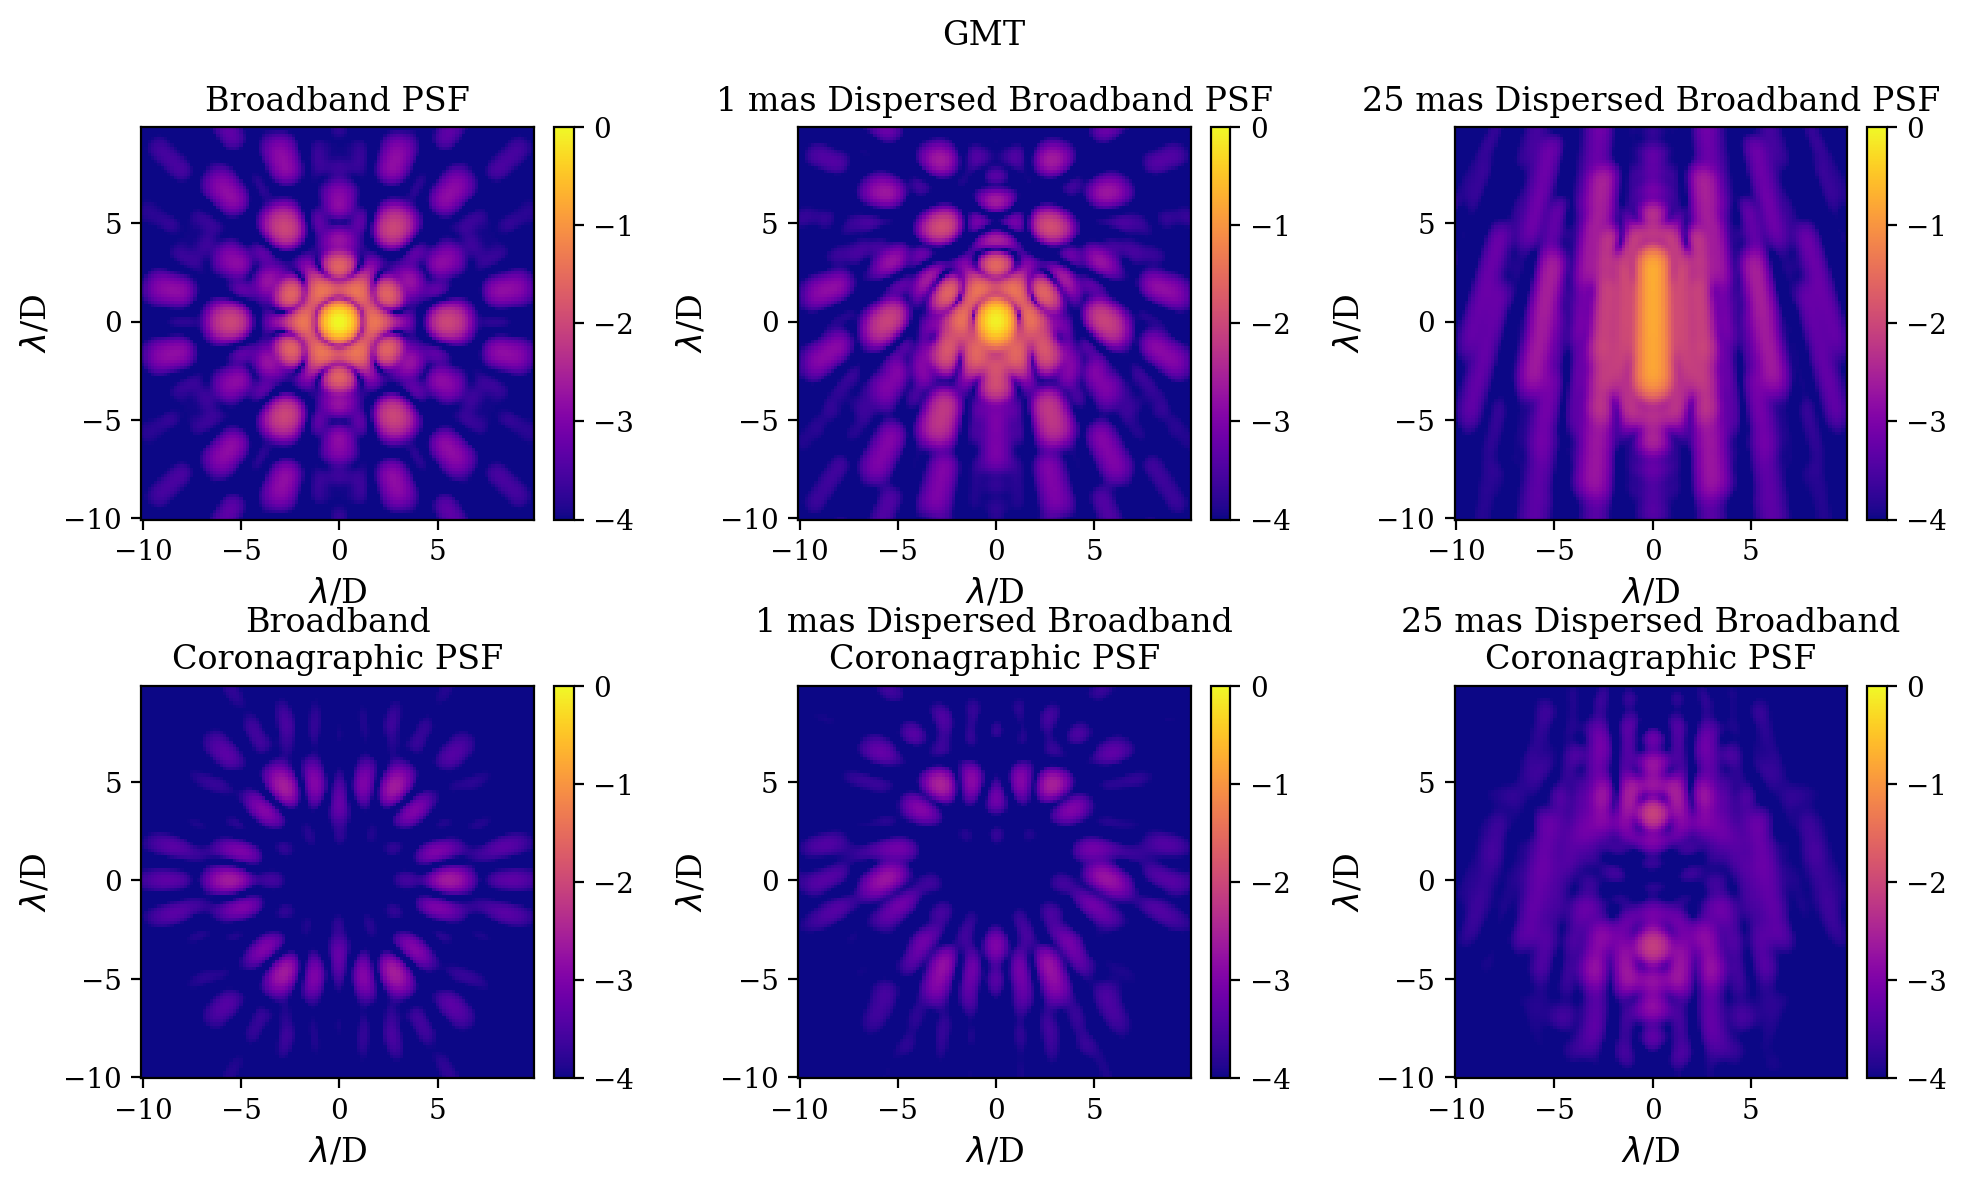

In [924]:
color = 'plasma'
fig, axs = plt.subplots(2,3,figsize=(10,6),dpi=200)

a = imshow_field(gmt_psf_bb,cmap=color,vmax=0,vmin=-4,ax=axs[0,0])
ca = colorbar(a)
axs[0,0].set_title('Broadband PSF')
axs[0,0].set_xlabel(r'$\lambda$/D')
axs[0,0].set_ylabel(r'$\lambda$/D')

b = imshow_field(gmt_psf_disp1,cmap=color,vmax=0,vmin=-4,ax = axs[0,1])
cb = colorbar(b)
axs[0,1].set_title('1 mas Dispersed Broadband PSF')
axs[0,1].set_xlabel(r'$\lambda$/D')
axs[0,1].set_ylabel(r'$\lambda$/D')

c = imshow_field(coron_gmt_psf_bb,cmap=color,vmax=0,vmin=-4,ax = axs[1,0])
cc = colorbar(c)
axs[1,0].set_title('Broadband\nCoronagraphic PSF')
axs[1,0].set_xlabel(r'$\lambda$/D')
axs[1,0].set_ylabel(r'$\lambda$/D')

d = imshow_field(coron_gmt_psf_disp1,cmap=color,vmax=0,vmin=-4, ax = axs[1,1])
cd = colorbar(d)
axs[1,1].set_title('1 mas Dispersed Broadband\nCoronagraphic PSF')
axs[1,1].set_xlabel(r'$\lambda$/D')
axs[1,1].set_ylabel(r'$\lambda$/D')

e = imshow_field(gmt_psf_disp25,cmap=color,vmax=0,vmin=-4, ax = axs[0,2])
ce = colorbar(e)
axs[0,2].set_title('25 mas Dispersed Broadband PSF')
axs[0,2].set_xlabel(r'$\lambda$/D')
axs[0,2].set_ylabel(r'$\lambda$/D')

f = imshow_field(coron_gmt_psf_disp25,cmap=color,vmax=0,vmin=-4, ax = axs[1,2])
cf = colorbar(f)
axs[1,2].set_title('25 mas Dispersed Broadband\nCoronagraphic PSF')
axs[1,2].set_xlabel(r'$\lambda$/D')
axs[1,2].set_ylabel(r'$\lambda$/D')

fig.suptitle('GMT')
fig.tight_layout(h_pad=.1)

In [ ]:
#fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/SPIE_26/gmt_coron.png')

I think the winner here is a figure with 1 mas and 25 mas of dispersion. We did it!